Group members: Stephanie Tiede, Corrine Bresky, Niecia Say

# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years?

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal:
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [ ]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"]
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"

In [ ]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,12.879967,12.534007,S-G1
1,1,osimertinib,B,tago-01560,-1.712741,11.650750,P
2,2,osimertinib,A,tago-02253,12.870441,12.998882,S-G1
3,3,osimertinib,A,tago-01478,15.319292,1.937557,S-syn
4,4,osimertinib,A,tago-02626,13.258777,12.765258,S-G1


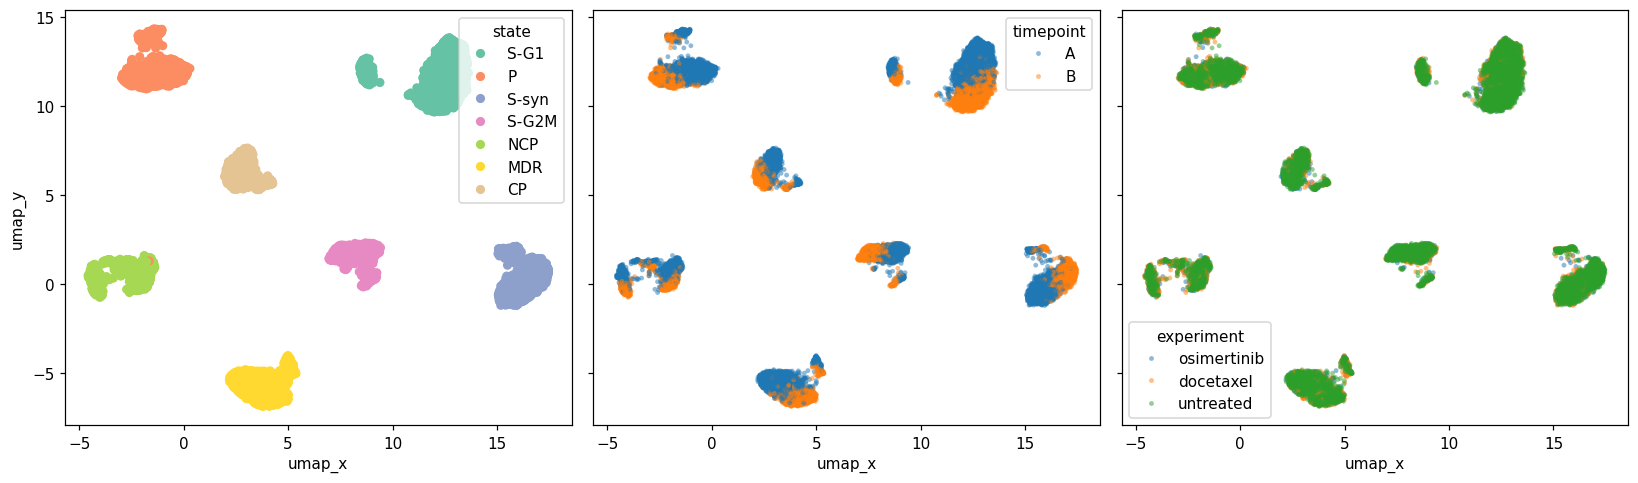

In [ ]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B.

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [ ]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [ ]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [ ]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [ ]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [ ]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [ ]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

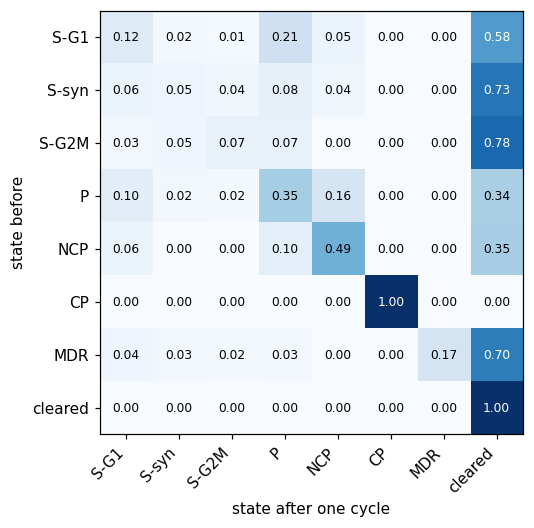

In [ ]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

**Yes. CP appears to be an absorbing state because its probability of remaining in CP is 1.00. We can see that the probabilities of transitioning to all the other states from CP are 0, meaning that CP has a 100% probability of remaining in that state. In terms of drug treatment, this suggests that CP cells persist under osimertinib treatment rather than transitioning to other states or being cleared.**

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it?

In [ ]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [ ]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [ ]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below.

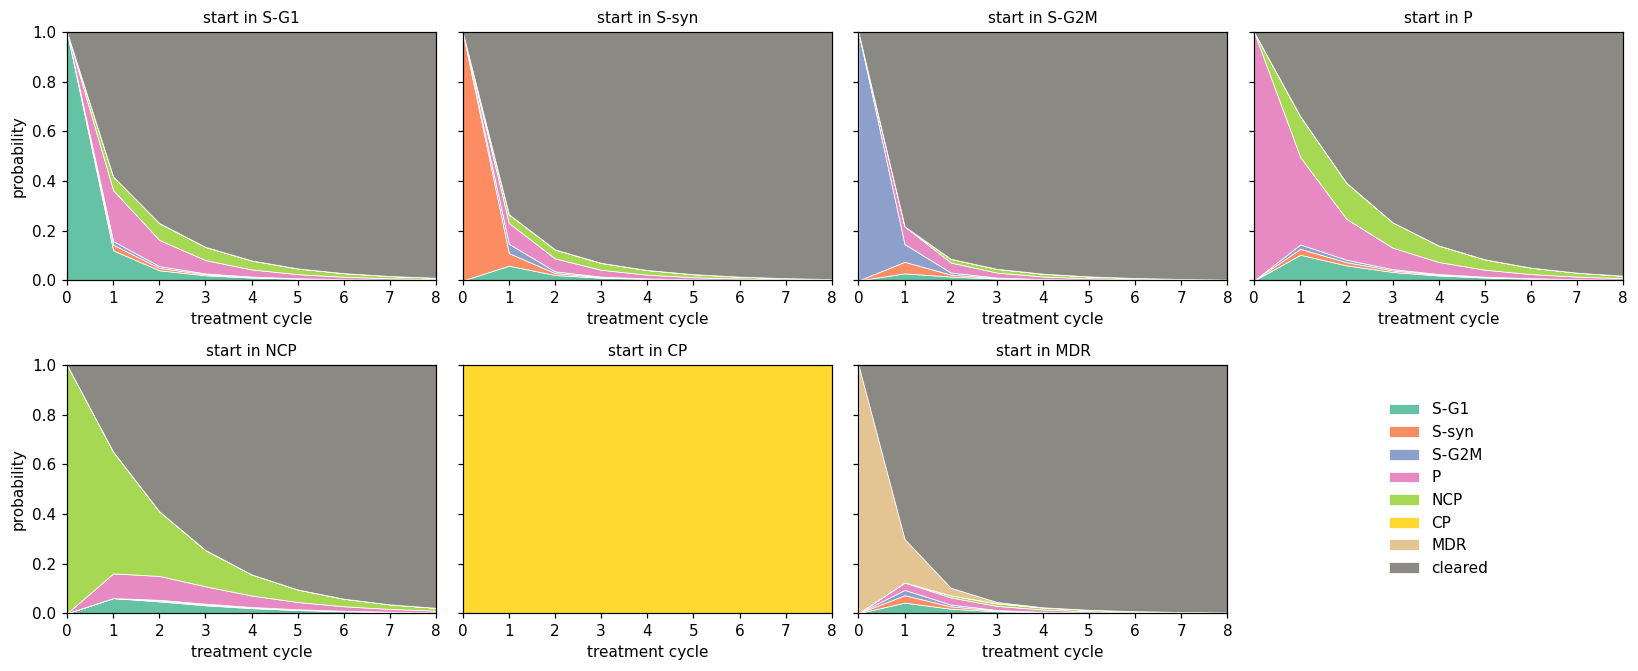

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [ ]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>



In [ ]:
# starting states
for n in [3,8,50]: # look at three different treatment cycle lengths
    print("Alive after", n, "cycles")

    for s in STATES: # go through each starting state
        alive = 1 - evolve(basis(s, P_hat), P_hat, n)[-1, -1] # calculate the probability of being alive after n cycles
        print(s, alive)

Alive after 3 cycles
S-G1 0.13515606012145576
S-syn 0.07070930791880914
S-G2M 0.04671693049692238
P 0.23436001531012585
NCP 0.25433624918151265
CP 1.0
MDR 0.04507722780004886
Alive after 8 cycles
S-G1 0.010811115609392852
S-syn 0.005620797724579796
S-G2M 0.003598547465694768
P 0.019025557100448065
NCP 0.02159271321724332
CP 1.0
MDR 0.0029481293241554463
Alive after 50 cycles
S-G1 9.178324766878632e-12
S-syn 4.771849582141385e-12
S-G2M 3.052336161601943e-12
P 1.616262679249303e-11
NCP 1.8376633548200516e-11
CP 1.0
MDR 2.4954482924499644e-12


- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
    - **The starting states that osimertinib completely eliminates are: S-G1, S-syn, S-G2M, P, MDR, and NCP. CP is still 100% alive even after 50 cycles.**
- Of the states that can be cleared, which tumor lasts the longest?
    - **Of the states that can be cleared, NCP lasts the longest.**
- Which starting state sticks around for the most cycles of drug?
    - **CP sticks around for every cycle of the treatment, so it sticks around for the most cycles of the drug.**
- Which starting state results in the highest proportion of alive cells after three cycles?
    - **CP is the starting state resulting in the highest proportion of alive cells after three cycles (1.0: 100% alive). If looking at just the states that can be cleared, then NCP has the highest proportion of alive cells after three cycles (around 0.2543; 25.43%).**

### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

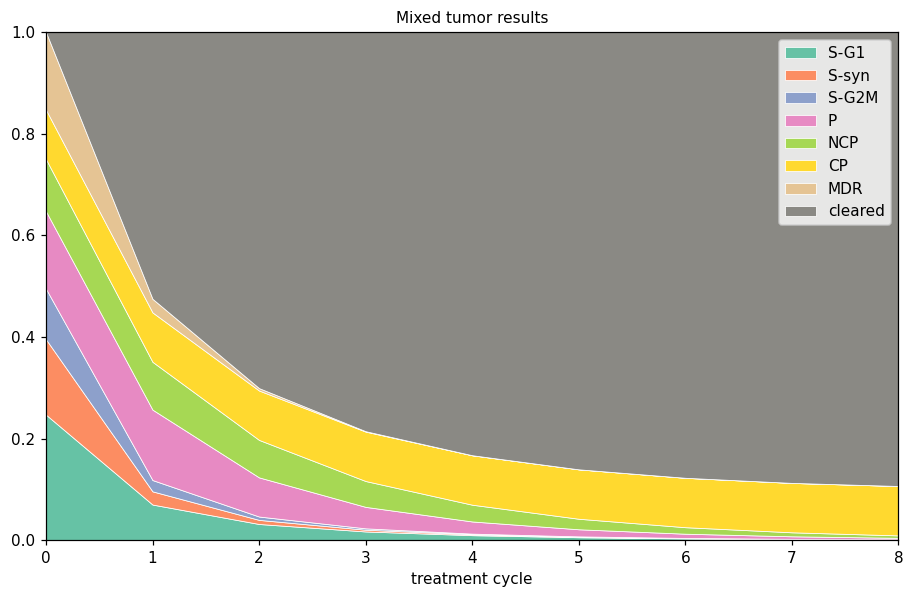

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247000,0.148333,0.099444,0.152556,0.102444,0.097222,1.530000e-01,0.000000
1,0.070114,0.025978,0.022220,0.138560,0.094096,0.097222,2.675053e-02,0.525059
2,0.031859,0.008083,0.006593,0.077011,0.073726,0.097222,4.677065e-03,0.700827
3,0.017174,0.003438,0.002694,0.042227,0.050873,0.097222,8.177385e-04,0.785555
4,0.009857,0.001733,0.001333,0.023930,0.032966,0.097222,1.429735e-04,0.832816
5,0.005821,0.000956,0.000728,0.013956,0.020710,0.097222,2.499749e-05,0.860582
6,0.003487,0.000552,0.000419,0.008292,0.012808,0.097222,4.370564e-06,0.877216
7,0.002104,0.000327,0.000248,0.004980,0.007857,0.097222,7.641498e-07,0.887262
8,0.001274,0.000196,0.000148,0.003008,0.004800,0.097222,1.336040e-07,0.893350


In [ ]:
# Your code here
timepoint_A = cells[cells['timepoint'] == 'A']

pi_mix = timepoint_A['state'].value_counts(normalize=True).reindex(OUTCOMES, fill_value=0) # set this equal to the starting vector from timepoint A

# evolve pi_mix and plot the results
pi_mix_trajectory = evolve(pi_mix, P_hat, N_CYCLES)
fig, ax = plt.subplots(figsize=(10, 6))
plot_trajectory(pi_mix_trajectory, ax, "Mixed tumor results")
ax.legend(loc='upper right')

plt.show()

pd.DataFrame(pi_mix_trajectory, columns=OUTCOMES)

<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?
- **The CP state ends up dominating the remaining cluster. The CP cells will not ever be cleared. We can see in the transition matrix that its share stays the same across the 8 cycles (0.097222). The long-run endpoint (where the tumor ends up if you keep treating it for a large number of cycles) relates to the transition matrix in that we can see directly how all of the probability of the other cells are absorbed/end up in "cleared", but cells that start as CP never leave CP and continues to make up 0.097222 of the tumor.**

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [ ]:
##Add code here
# following code from step 2/3

# DOCETAXEL
doc = cells[cells["experiment"] == "docetaxel"]
at_A = doc[doc.timepoint == "A"][["lineage_tag", "state"]]
at_B = doc[doc.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_doc = counts.div(counts.sum(axis=1), axis=0)

assert np.allclose(P_doc.sum(axis=1), 1), "Every row should sum to 1."

#add a cleared row that stays cleared with p = 1
P_doc.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_doc.columns})

# DRUG HOLIDAY ("untreated")
untreated = cells[cells["experiment"] == "untreated"]
at_A = untreated[untreated.timepoint == "A"][["lineage_tag", "state"]]
at_B = untreated[untreated.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_holiday = counts.div(counts.sum(axis=1), axis=0)

assert np.allclose(P_holiday.sum(axis=1), 1), "Every row should sum to 1."

#add a cleared row that stays cleared with p = 1
P_holiday.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_holiday.columns})

# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position
P_osi = P_hat.to_numpy()
P_doc_notnumpy = P_doc
P_doc = P_doc.to_numpy()
P_holiday = P_holiday.to_numpy()

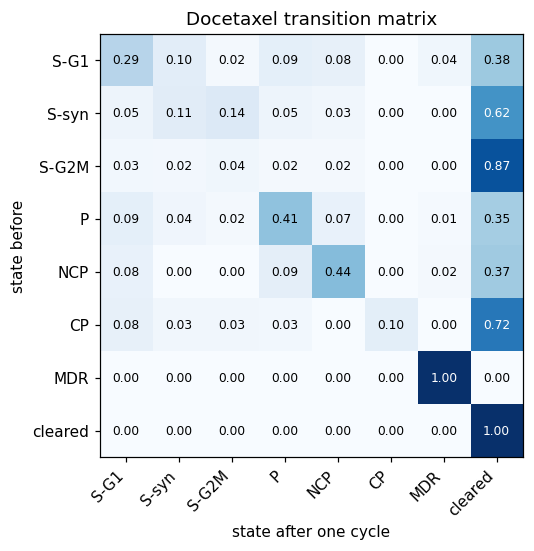

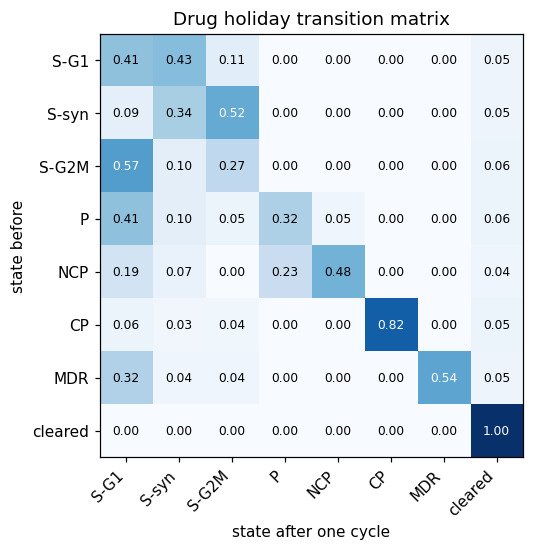

In [ ]:
#Plot the transition matrices for docetaxel and the drug holiday.
P_doc_df = pd.DataFrame(P_doc, index=OUTCOMES, columns=OUTCOMES)
P_holiday_df = pd.DataFrame(P_holiday, index=OUTCOMES, columns=OUTCOMES)

show_matrix(P_doc_df, "Docetaxel transition matrix")
show_matrix(P_holiday_df, "Drug holiday transition matrix")

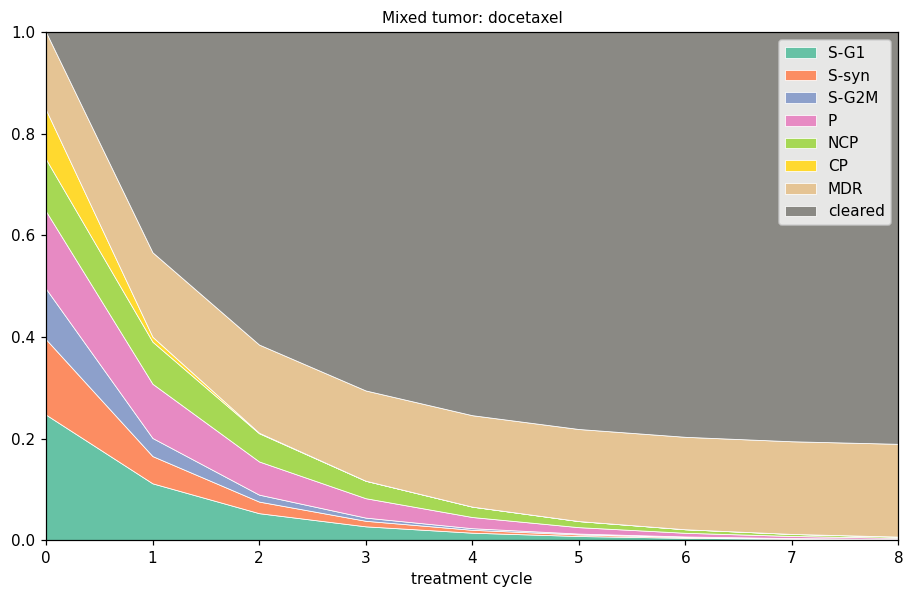

In [ ]:
# Simulate the evolution of pi_mix under docetaxel
docetaxel_traj = evolve(pi_mix, P_doc, N_CYCLES)

fig, ax = plt.subplots(figsize=(10, 6))
plot_trajectory(docetaxel_traj, ax, "Mixed tumor: docetaxel")
ax.legend()
plt.show()

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
- **Looking at the transition matrix under docetaxel, we can see that MDR is now the absorbing state (it stays at 1.0 probability and does not clear, just as CP did under osimertinib treatment). CP is now cleared with a probability of 0.72. Looking at the transition matrix under the drug holiday, there is no absorbing state other than "cleared". Every state (except "cleared") ranges from 0.04-0.06 in the "cleared" column, meaning most of the cells stay alive after each cycle and they mostly just transition between cell states instead of dying.**
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?
- **When simulating the mixed tumor under multiple rounds of docetaxel, it now looks like MDR and cleared are dominating. After 8 cycles, it looks like almost all of the tumor cells that are still alive are MDR, and the MDR cells are never cleared.**

## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

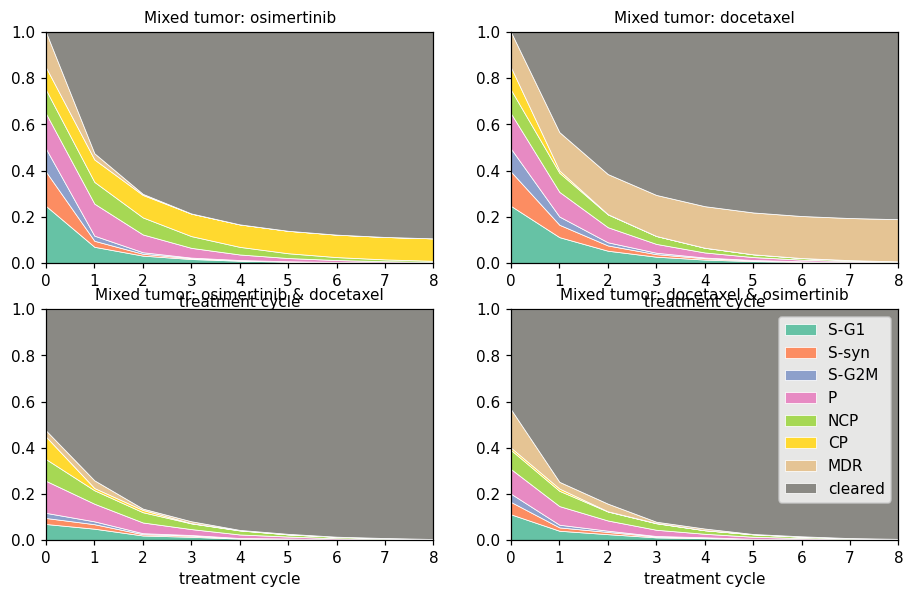

In [ ]:

fig, ax = plt.subplots(2, 2, figsize=(10, 6))

# Osi
osimertinib_traj = evolve(pi_mix, P_hat, 8)
plot_trajectory(osimertinib_traj, ax[0,0], "Mixed tumor: osimertinib")


# Doc
docetaxel_traj = evolve(pi_mix, P_doc, 8)
plot_trajectory(docetaxel_traj, ax[0,1], "Mixed tumor: docetaxel")


# Osi first, then Doc
bases = []
for i in range(9):
  if i == 0:
    basis = evolve(pi_mix, P_hat, 1)[-1]
  elif i % 2 == 0:
    basis = evolve(basis, P_hat, 1)[-1]
  else:
    basis = evolve(basis, P_doc, 1)[-1]
  bases.append(basis)

testing = pd.DataFrame(bases)
plot_trajectory(testing, ax[1,0], "Mixed tumor: osimertinib & docetaxel")


# Doc first, then Osi
bases = []
for i in range(9):
  if i == 0:
    basis = evolve(pi_mix, P_doc, 1)[-1]
  elif i % 2 == 0:
    basis = evolve(basis, P_doc, 1)[-1]
  else:
    basis = evolve(basis, P_hat, 1)[-1]
  bases.append(basis)

testing = pd.DataFrame(bases)
plot_trajectory(testing, ax[1,1], "Mixed tumor: docetaxel & osimertinib")
ax[1,1].legend()


plt.show()



*Answer questions here.*

1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - **For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.**

**Osimertinib appears to be more aggressive towards cells in the MDR stage than Docetaxel and Docetaxel appears to be more aggressive towards cells in the CP stage than Osimertinib. When they alternate, the proportion of MDR and CP cells decreases more than they do when only treated with one treatment.**


2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?

**When Osimertinib is applied first, the proportion of MDR stage cells is smaller than when Docetaxel is applied first. The reverse is true for CP, where if Docetaxel is applied first the proportion of CP stage cells is smaller than when Osimertinib is applied first.**


3.  In what situation would a drug holiday help clear the tumor?

**A drug holiday may help clear a tumor when the proportion of a target cell is no longer decreasing, and maybe could be used when alternating treatments. For example, one could treat one type of cell for a few cycles and then take a holiday while starting a different treatment that targets a different cell.**


4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.


**We recommend a combination of treatments under the assumption that starting states are unlikely to be uniform in a tumor. When there are mixed cell stages in a tumor, we see that undergoing the Osimertinib treatment in the first cycle tends to bring the overall tumor cell count lower than when starting with Docetaxel. Since CP cells respond more to Docetaxel, we would like to also include it in the treatment plan. Overall, it appears that alternating Osimertinib and Docetaxel is the best method in bringing the overall tumor cell count down, specifically starting with Osimertinib. Each treatment includes 8 rounds, but we see above that alternating gives us the same proportion of overall tumor cells at cycle 3 that other methods only achieve after 8 rounds.**

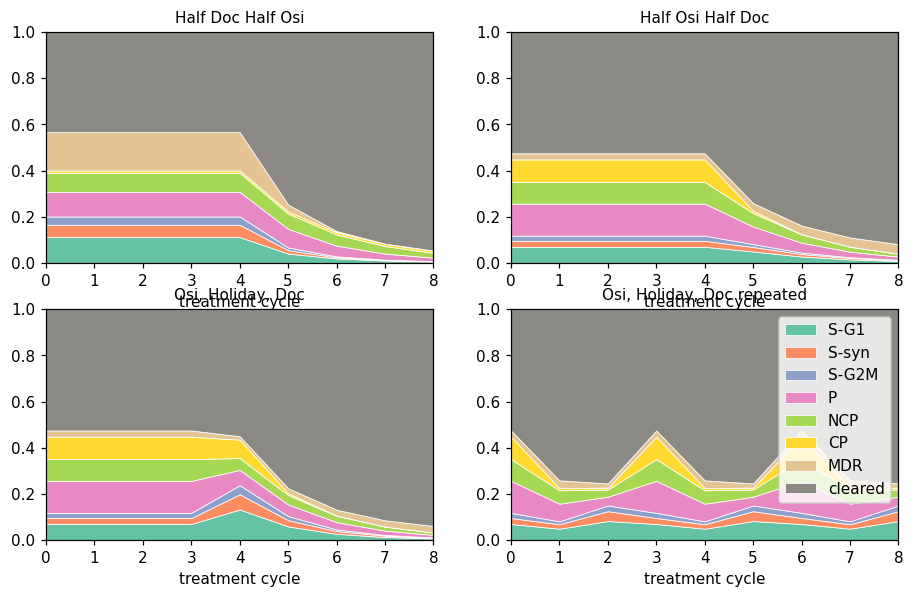

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(10, 6))

# Half Doc Half Osi

bases = []
for i in range(9):
  if i < 5:
    basis = evolve(pi_mix, P_doc, 1)[-1]
  else:
    basis = evolve(basis, P_hat, 1)[-1]
  bases.append(basis)

testing = pd.DataFrame(bases)
plot_trajectory(testing, ax[0,0], "Half Doc Half Osi")

# Half Osi Half Doc

bases = []
for i in range(9):
  if i < 5:
    basis = evolve(pi_mix, P_hat, 1)[-1]
  else:
    basis = evolve(basis, P_doc, 1)[-1]
  bases.append(basis)

testing = pd.DataFrame(bases)
plot_trajectory(testing, ax[0,1], "Half Osi Half Doc")

# Osi, Holiday, Doc

bases = []
for i in range(9):
  if i < 4:
    basis = evolve(pi_mix, P_hat, 1)[-1]
  elif i < 5:
    basis = evolve(basis, P_holiday, 1)[-1]
  else:
    basis = evolve(basis, P_doc, 1)[-1]
  bases.append(basis)

testing = pd.DataFrame(bases)
plot_trajectory(testing, ax[1,0], "Osi, Holiday, Doc")

# Osi, Holiday, Doc on repeat

bases = []
for i in range(9):
  if i in [0,3,6]:
    basis = evolve(pi_mix, P_hat, 1)[-1]
  elif i in [1,4,7]:
    basis = evolve(basis, P_doc, 1)[-1]
  else:
    basis = evolve(basis, P_holiday, 1)[-1]
  bases.append(basis)

testing = pd.DataFrame(bases)
plot_trajectory(testing, ax[1,1], "Osi, Holiday, Doc repeated")

ax[1,1].legend()


plt.show()

## 4 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities.

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [ ]:
rng = np.random.default_rng(100)

In [ ]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [ ]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

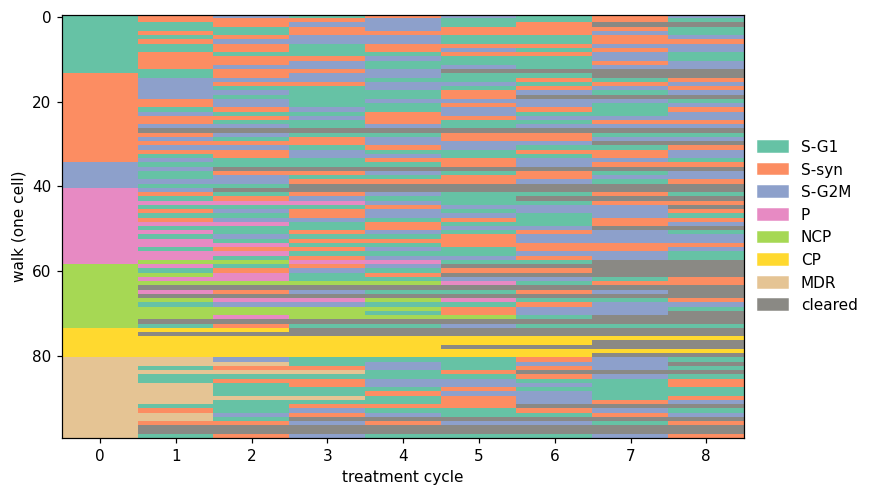

In [ ]:
N_WALKS = 100
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [ ]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

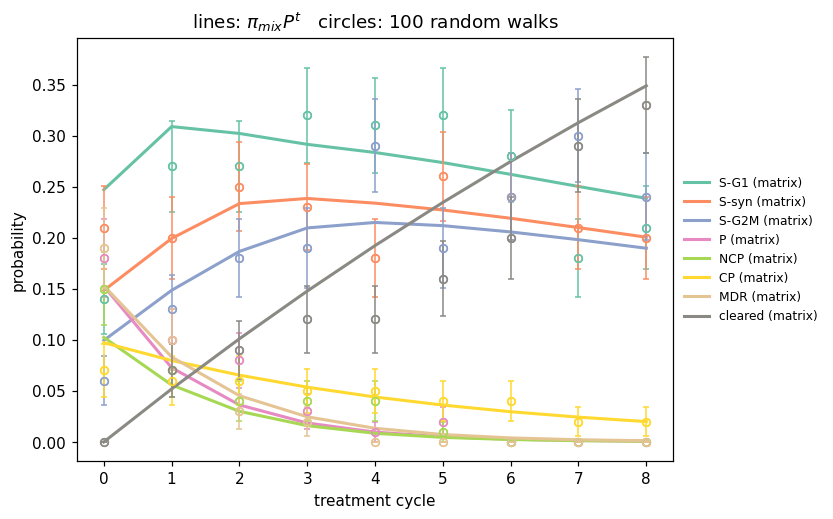

In [ ]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>


**The gap between the circles and lines changes when the number of walks (cells) increases because there is less variability in the data as we increase our sample size. The lines and circles are more aligned when the number of walks is 10,000 than 100.**

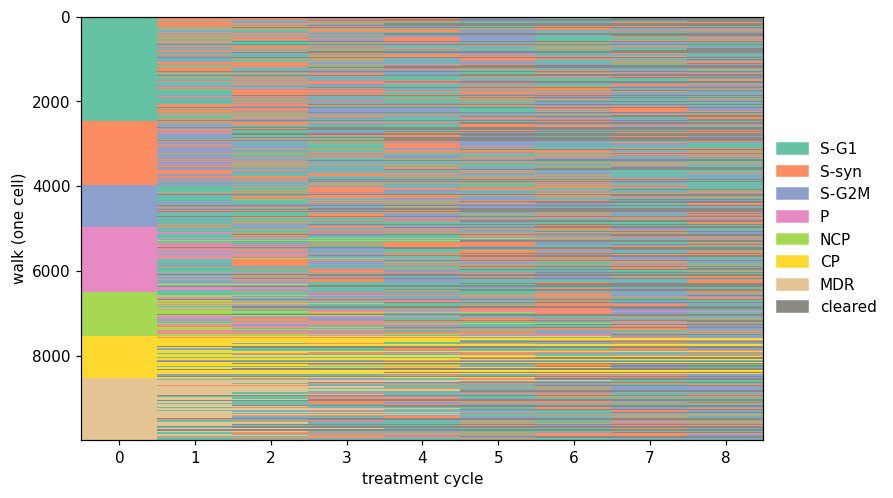

In [ ]:
N_WALKS = 10_000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

In [ ]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

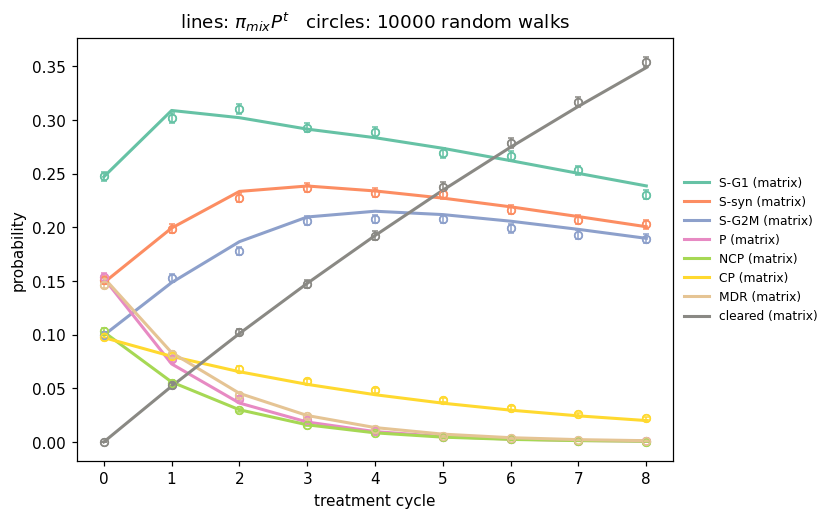

In [ ]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [ ]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

In [ ]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

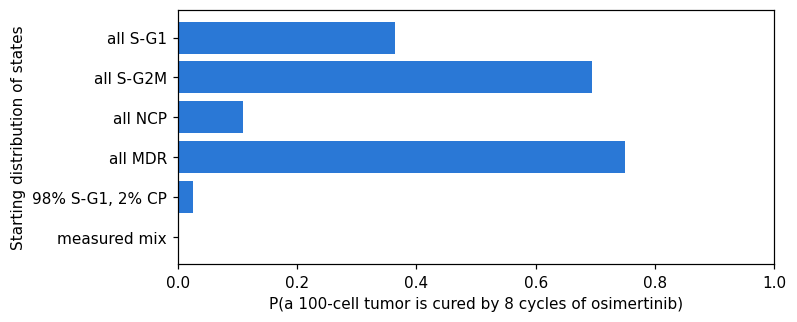

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.365,1.025,0.000
all S-G2M,0.695,0.345,0.000
all NCP,0.110,2.140,0.000
all MDR,0.750,0.275,0.000
"98% S-G1, 2% CP",0.025,3.190,0.638
measured mix,0.000,10.685,0.918


In [ ]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_osi, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

**When rerunning the code with all docetaxel, the results show that a tumor made up of only S-G2M stage cells has about a 0.57 chance of being cured with 8 cycles of docetaxel, while all other tumors have very low chances if any.**

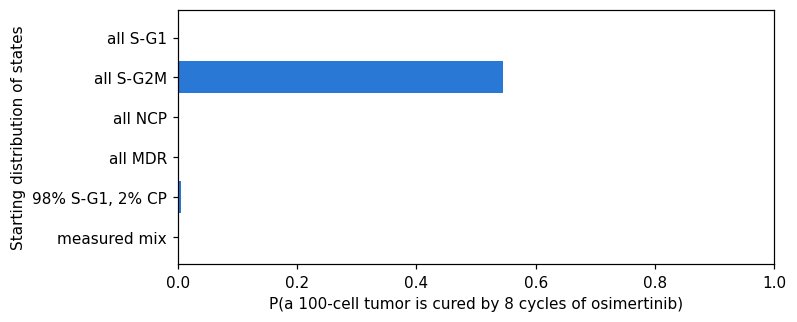

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.000,7.805,0.0
all S-G2M,0.545,0.610,0.0
all NCP,0.000,6.690,0.0
all MDR,0.000,100.000,0.0
"98% S-G1, 2% CP",0.005,6.985,0.0
measured mix,0.000,18.955,0.0


In [ ]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_doc, 8      # this simulation: 8 cycles of docetaxel
scenarios = {
    "all S-G1":       basis("S-G1", P_doc_notnumpy),
    "all S-G2M":      basis("S-G2M", P_doc_notnumpy),
    "all NCP":         basis("NCP", P_doc_notnumpy),
    "all MDR":        basis("MDR", P_doc_notnumpy),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_doc_notnumpy) + 0.02 * basis("CP", P_doc_notnumpy),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles.

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles.

In [ ]:
def walk_dataframe(cell_count, n_cycle, pi0, P, rng):
  test_df = pd.DataFrame()

  for _ in range(cell_count):
    start = rng.choice(len(pi0), size=1, p=pi0).item()
    test = []

    for i in random_walk(start, P_osi, n_cycle, rng): #P_osi
      test.append(OUTCOMES[i])

    test_df = pd.concat([test_df, pd.DataFrame(test)], axis = 1, ignore_index = True)

  return test_df

test_df = walk_dataframe(1000, 8, pi_mix, P_osi, rng).T
test_df.head()

,0,1,2,3,4,5,6,7,8
0,S-syn,cleared,cleared,cleared,cleared,cleared,cleared,cleared,cleared
1,P,cleared,cleared,cleared,cleared,cleared,cleared,cleared,cleared
2,CP,CP,CP,CP,CP,CP,CP,CP,CP
3,MDR,MDR,cleared,cleared,cleared,cleared,cleared,cleared,cleared
4,P,cleared,cleared,cleared,cleared,cleared,cleared,cleared,cleared


In [ ]:
def clean_persist(df):

  persist_states = ['P', 'NCP']
  df_persist = df[df.isin(persist_states).any(axis=1)] #Remove rows without P or NCP
  df_bool = df_persist.isin(['P', 'NCP']) #Convert cells to T/F based on whether they contain P/NCP or not
  df_persist = df_persist[df_bool.sum(axis=1) >= 3] #Remove rows that have less than 3 appearances of P/NCP

  return df_persist

hi_df = clean_persist(test_df)
hi_df.head()

,0,1,2,3,4,5,6,7,8
23,NCP,NCP,NCP,NCP,NCP,NCP,NCP,cleared,cleared
28,P,P,NCP,cleared,cleared,cleared,cleared,cleared,cleared
33,P,P,P,P,cleared,cleared,cleared,cleared,cleared
53,P,P,P,S-G1,S-syn,cleared,cleared,cleared,cleared
56,P,P,P,P,cleared,cleared,cleared,cleared,cleared


In [ ]:
def count_consecutive(df):

  df_bool = df.isin(['P', 'NCP'])
  test = df_bool.T
  consec_check = []

  for u in range(len(df)):
    y = test.iloc[:,u]
    test_list = list(y * (y.groupby((y != y.shift()).cumsum()).cumcount() + 1)) #count how many consecutive groups of P/NCP there are
    consec_check.append(any(x >= 3 for x in test_list))

  return sum(consec_check)

count_consecutive(hi_df)

104

In [ ]:
# write a function that runs 1000 random walks and saves them
# you will use this function 100 times to generate a simulated set of tumors

# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally
# count up cells that stayed in persister state consecutively out of total cells

# repeat for all tumors

def overall(cell_count, tumor_count, n_cycle, pi0, P, rng):

  consecutive_list = []

  for y in range(tumor_count):

    test_df = walk_dataframe(cell_count, n_cycle, pi0, P, rng).T

    clean_df = clean_persist(test_df)

    consecutive_list.append(count_consecutive(clean_df))

  return consecutive_list


In [ ]:
tumor_persist = overall(cell_count = 1000, tumor_count = 100, n_cycle = 8, pi0 = pi_mix, P = P_osi, rng = rng) #takes about 2 minutes to run

In [ ]:
tumor_osi = np.array(tumor_persist)

In [ ]:
x_bar = ((tumor_osi/1000).mean())*100
sem = ((tumor_osi/1000).std()/np.sqrt(100))*100
print(f'mean: {x_bar}, sem: {sem}')

mean: 11.631000000000002, sem: 0.10407396408324227


In [ ]:
# report mean +/- SEM for osimertinib

print(f'mean +/- SEM: ({x_bar - sem}, {x_bar + sem})')

mean +/- SEM: (11.526926035916759, 11.735073964083245)


In [ ]:
from scipy import stats

t_critical = stats.t.ppf(0.975, df=99)

lower = x_bar - t_critical * sem
upper = x_bar + t_critical * sem

print(f"95% CI: ({lower:.2f}%, {upper:.2f}%)")

95% CI: (11.42%, 11.84%)


In [ ]:
def persister_state(n_cells=1000):
    starts = rng.choice(len(pi_mix), size=n_cells, p=pi_mix)
    walks = np.array([
        random_walk(int(s), P_osi, N_TUMOR_CYCLES, rng)
        for s in starts
    ])
    return walks

PERSISTER_STATES = ["P", "NCP"]
persister_indices = [
    OUTCOMES.index(state) for state in PERSISTER_STATES
]
#The function checks each cell's path, counts how many consecutive cycles it spends in P or NCP
#and considers it permanently resistant once it reaches 3 consecutive cycles
def count_persisters(walks):
    count = 0
    # Loop through each cell's path
    for walk in walks:
        consecutive = 0
         # Skip the initial state and examine the treatment cycles
        for state in walk[1:]:
            if state in persister_indices:
                consecutive += 1
            else:
                consecutive = 0
            if consecutive >= 3:
                count += 1
                break
    return count / len(walks) * 100

N_TUMORS = 100
tumor_percentages = []

# Simulate N_TUMORS different tumors
for i in range(N_TUMORS):
    walks = persister_state(n_cells=1000)
    percentage = count_persisters(walks)
    tumor_percentages.append(percentage)

tumor_percentages = np.array(tumor_percentages)
mean_persisters = tumor_percentages.mean()
sem_persisters = (
    tumor_percentages.std(ddof=1) / np.sqrt(N_TUMORS)
)
print(f"Mean: {mean_persisters:.2f}%")
print(f"SEM: {sem_persisters:.2f}%")


Mean: 8.24%
SEM: 0.08%


<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

In [ ]:
# Alternating OD functions

def random_walk_two(start, P1, P2, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for f in range(n_cycles):
      if f % 2 == 0:
        path.append(step(path[-1], P1, rng))
      else:
        path.append(step(path[-1], P2, rng))

    return path


def walk_dataframe_OD(cell_count, P1, P2, n_cycle, pi0, rng):
  test_df = pd.DataFrame()

  for _ in range(cell_count):
    start = rng.choice(len(pi0), size=1, p=pi0).item()
    test = []


    for i in random_walk_two(start, P1, P2, n_cycle, rng): #P_osi
      test.append(OUTCOMES[i])

    test_df = pd.concat([test_df, pd.DataFrame(test)], axis = 1, ignore_index = True)

  return test_df


def overall_two(cell_count, tumor_count, P1, P2, n_cycle, pi0, rng):

  consecutive_list = []

  for y in range(tumor_count):

    test_df = walk_dataframe_OD(cell_count, P1, P2, n_cycle, pi0, rng).T

    clean_df = clean_persist(test_df)

    consecutive_list.append(count_consecutive(clean_df))

  return consecutive_list



In [ ]:
# Doxetaxel with drug holiday functions

def random_walk_holiday(start, P1, P2, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for f in range(n_cycles):
      if f == f/2:
        path.append(step(path[-1], P1, rng))
      else:
        path.append(step(path[-1], P2, rng))

    return path


def walk_dataframe_holiday(cell_count, P1, P2, n_cycle, pi0, rng):
  test_df = pd.DataFrame()

  for _ in range(cell_count):
    start = rng.choice(len(pi0), size=1, p=pi0).item()
    test = []


    for i in random_walk_holiday(start, P1, P2, n_cycle, rng): #P_osi
      test.append(OUTCOMES[i])

    test_df = pd.concat([test_df, pd.DataFrame(test)], axis = 1, ignore_index = True)

  return test_df


def overall_holiday(cell_count, tumor_count, P1, P2, n_cycle, pi0, rng):

  consecutive_list = []

  for y in range(tumor_count):

    test_df = walk_dataframe_holiday(cell_count, P1, P2, n_cycle, pi0, rng).T

    clean_df = clean_persist(test_df)

    consecutive_list.append(count_consecutive(clean_df))

  return consecutive_list

In [ ]:
# Percent of each that have higher than 10%
osi_10 = []
doc_10 = []
OD_10 = []
hol_10 = []
tum_count = 20 #Smaller tumor and cell counts so the code does not run for a long time
cell_ct = 50

for a in range(9):
  osi_over = (np.array(overall(cell_count = cell_ct, tumor_count = tum_count, n_cycle = a, pi0 = pi_mix, P = P_osi, rng = rng))/tum_count > 0.1).mean()
  osi_10.append(osi_over)
  doc_over = (np.array(overall(cell_count = cell_ct, tumor_count = tum_count, n_cycle = a, pi0 = pi_mix, P = P_doc, rng = rng))/tum_count > 0.1).mean()
  doc_10.append(doc_over)
  OD_over = (np.array(overall_two(cell_count = cell_ct, tumor_count = tum_count, P1 = P_osi, P2 = P_doc, n_cycle = a, pi0 = pi_mix, rng = rng))/tum_count > 0.1).mean()
  OD_10.append(OD_over)
  hol_over = (np.array(overall_holiday(cell_count = cell_ct, tumor_count = tum_count, P1 = P_holiday, P2 = P_doc, n_cycle = a, pi0 = pi_mix, rng = rng))/tum_count > 0.1).mean()
  hol_10.append(hol_over)


In [ ]:
# Dataframe
over10_df = pd.DataFrame({'Cycles': list(range(1,10)),
              'Osi': osi_10,
              'Doc': doc_10,
              'OD': OD_10,
              'Holiday': hol_10})

In [ ]:
over10_df

,Cycles,Osi,Doc,OD,Holiday
0,1,0.00,0.00,0.00,0.00
1,2,0.00,0.00,0.00,0.00
2,3,0.90,0.70,0.75,0.50
3,4,1.00,0.95,0.90,0.50
4,5,0.85,0.95,0.85,0.95
5,6,0.90,1.00,0.85,0.90
6,7,0.90,0.85,0.85,0.85
7,8,0.95,0.95,1.00,0.90
8,9,0.90,0.80,0.95,0.90


[link text](https://)<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>


**As the number of cycles increase, most notably after two cycles, the percentage of tumors under all the treatments over 10% increases with some variation as the percentage reaches 90%. None of the treatments have tumors with over 10% permanently resistant cells because the qualification to be a resistant cell is to be in the same state of P or NCP for three consecutive cycles, which is not possible at cycle 1 and 2.**

**At cycle 8, 90% of tumors treated with Osimertinib alone have more than 10% permanently resistant cells, 80% of tumors treated with Doxetaxel alone have more than 10% permanently resistant cells, 95% of tumors treated with alternating OD have more than 10% permanently resistant cells, and 90% of tumors treated with Doxetaxel and a drug holiday have more than 10% permanently resistant cells.**